# ClaimGuard AI — Week 2: Baseline Modeling & Evaluation

Trains a regularized Logistic Regression baseline and an XGBoost ensemble on `fraud_oracle.csv`,
using a stratified 60/20/20 train/validation/test split. All preprocessing (imputation, scaling,
one-hot encoding) is fit **only on the training fold**, via `src/features/build_features.py`.

**Reminder of scope:** `FraudFound_P` is a dataset-defined historical flag (1994–1996), not a
verified fraud determination. All metrics below describe held-out performance on this one
historical dataset only.

## 1. Load, engineer, split

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from src.data.load import load_raw
from src.models.train import (
    split_data, xy, build_logistic_regression_pipeline,
    build_xgboost_pipeline, compute_scale_pos_weight, RANDOM_STATE,
)
from src.models.evaluate import classification_metrics, precision_recall_at_k

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

df = load_raw('../data/raw/fraud_oracle.csv')
print('Loaded and schema-validated:', df.shape)

train_df, val_df, test_df = split_data(df)
print('Train:', train_df.shape, 'positive rate:', train_df['FraudFound_P'].mean().round(4))
print('Val:  ', val_df.shape, 'positive rate:', val_df['FraudFound_P'].mean().round(4))
print('Test: ', test_df.shape, 'positive rate:', test_df['FraudFound_P'].mean().round(4))


Loaded and schema-validated: (15420, 33)
Train: (9252, 33) positive rate: 0.0599
Val:   (3084, 33) positive rate: 0.0597
Test:  (3084, 33) positive rate: 0.06


In [2]:
X_train, y_train = xy(train_df)
X_val, y_val = xy(val_df)
X_test, y_test = xy(test_df)

print('Feature frame shape (pre-encoding):', X_train.shape)
X_train.head()


Feature frame shape (pre-encoding): (9252, 31)


,WeekOfMonth,WeekOfMonthClaimed,Age,Deductible,DriverRating,Year,AgeUnknown,Month,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,Sex,MaritalStatus,Fault,PolicyType,VehicleCategory,VehiclePrice,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,BasePolicy
2214,4,1,33.0,400,2,1994,0,Mar,Wednesday,Pontiac,Urban,Tuesday,Apr,Male,Single,Policy Holder,Sedan - All Perils,Sedan,20000 to 29000,more than 30,more than 30,1,7 years,31 to 35,No,No,External,more than 5,no change,3 to 4,All Perils
6615,1,3,44.0,400,4,1995,0,Nov,Sunday,Honda,Urban,Friday,Nov,Male,Married,Third Party,Sedan - All Perils,Sedan,20000 to 29000,more than 30,more than 30,1,more than 7,36 to 40,No,No,External,3 to 5,4 to 8 years,2 vehicles,All Perils
5427,2,3,32.0,400,3,1994,0,Nov,Saturday,Mazda,Rural,Wednesday,Nov,Male,Single,Third Party,Sedan - Collision,Sedan,20000 to 29000,more than 30,more than 30,2 to 4,6 years,31 to 35,No,No,External,1 to 2,no change,1 vehicle,Collision
10819,3,5,49.0,700,4,1995,0,Feb,Wednesday,Chevrolet,Urban,Tuesday,Feb,Male,Married,Third Party,Sedan - All Perils,Sedan,30000 to 39000,more than 30,more than 30,2 to 4,more than 7,41 to 50,No,No,External,none,no change,1 vehicle,All Perils
10791,4,4,30.0,400,3,1995,0,Apr,Sunday,Mazda,Urban,Monday,Apr,Male,Married,Policy Holder,Sedan - Collision,Sedan,30000 to 39000,more than 30,more than 30,none,6 years,31 to 35,No,No,External,none,no change,1 vehicle,Collision


## 2. Baseline: regularized Logistic Regression

`class_weight='balanced'` is used instead of resampling, so no synthetic rows are created and
there is no risk of leaking resampled duplicates across folds. Fit on train only; scored on
validation.

In [3]:
lr_pipeline = build_logistic_regression_pipeline()
lr_pipeline.fit(X_train, y_train)

lr_val_prob = lr_pipeline.predict_proba(X_val)[:, 1]
lr_val_metrics = classification_metrics(y_val, lr_val_prob)
lr_val_metrics


{'threshold': 0.5,
 'roc_auc': 0.7977473763118441,
 'pr_auc': 0.15367292382036443,
 'precision': 0.13321647677475898,
 'recall': 0.8260869565217391,
 'f1': 0.22943396226415094,
 'brier_score': 0.17731063218066542,
 'confusion_matrix': {'tn': 1911, 'fp': 989, 'fn': 32, 'tp': 152},
 'positive_prevalence': 0.05966277561608301}

## 3. Candidate: XGBoost

`scale_pos_weight` is computed from the **training fold only** to avoid leaking validation/test class balance into the model.

In [4]:
spw = compute_scale_pos_weight(y_train)
print('scale_pos_weight (train-only):', round(spw, 3))

xgb_pipeline = build_xgboost_pipeline(scale_pos_weight=spw)
xgb_pipeline.fit(X_train, y_train)

xgb_val_prob = xgb_pipeline.predict_proba(X_val)[:, 1]
xgb_val_metrics = classification_metrics(y_val, xgb_val_prob)
xgb_val_metrics


scale_pos_weight (train-only): 15.7


{'threshold': 0.5,
 'roc_auc': 0.8424812593703149,
 'pr_auc': 0.2553434663491514,
 'precision': 0.1732186732186732,
 'recall': 0.7663043478260869,
 'f1': 0.28256513026052105,
 'brier_score': 0.12743592229518924,
 'confusion_matrix': {'tn': 2227, 'fp': 673, 'fn': 43, 'tp': 141},
 'positive_prevalence': 0.05966277561608301}

## 4. Validation comparison

In [5]:
comparison = pd.DataFrame([
    {'model': 'Logistic Regression', **{k: v for k, v in lr_val_metrics.items() if k not in ('confusion_matrix',)}},
    {'model': 'XGBoost', **{k: v for k, v in xgb_val_metrics.items() if k not in ('confusion_matrix',)}},
]).set_index('model')
comparison


,threshold,roc_auc,pr_auc,precision,recall,f1,brier_score,positive_prevalence
model,,,,,,,,
Logistic Regression,0.5,0.797747,0.153673,0.133216,0.826087,0.229434,0.177311,0.059663
XGBoost,0.5,0.842481,0.255343,0.173219,0.766304,0.282565,0.127436,0.059663


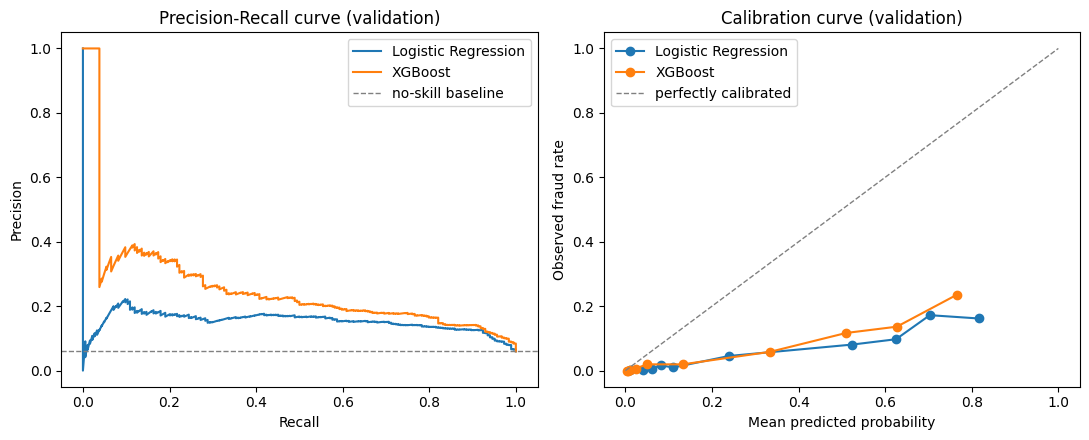

In [6]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for name, prob in [('Logistic Regression', lr_val_prob), ('XGBoost', xgb_val_prob)]:
    prec, rec, _ = precision_recall_curve(y_val, prob)
    axes[0].plot(rec, prec, label=name)
axes[0].axhline(y_val.mean(), color='gray', linestyle='--', linewidth=1, label='no-skill baseline')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall curve (validation)')
axes[0].legend()

from sklearn.calibration import calibration_curve
for name, prob in [('Logistic Regression', lr_val_prob), ('XGBoost', xgb_val_prob)]:
    frac_pos, mean_pred = calibration_curve(y_val, prob, n_bins=10, strategy='quantile')
    axes[1].plot(mean_pred, frac_pos, marker='o', label=name)
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='perfectly calibrated')
axes[1].set_xlabel('Mean predicted probability'); axes[1].set_ylabel('Observed fraud rate')
axes[1].set_title('Calibration curve (validation)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/figures/pr_and_calibration_val.png', dpi=150)
plt.show()


## 5. Model selection

Selection is based on **validation PR-AUC** (the right metric under ~6% prevalence — ROC-AUC can
look optimistic on imbalanced data). The test set has not been touched by either model or this
decision.

In [7]:
selected_name = 'XGBoost' if xgb_val_metrics['pr_auc'] >= lr_val_metrics['pr_auc'] else 'Logistic Regression'
selected_pipeline = xgb_pipeline if selected_name == 'XGBoost' else lr_pipeline
print('Selected model (by validation PR-AUC):', selected_name)
print('LR val PR-AUC: ', round(lr_val_metrics['pr_auc'], 4))
print('XGB val PR-AUC:', round(xgb_val_metrics['pr_auc'], 4))


Selected model (by validation PR-AUC): XGBoost
LR val PR-AUC:  0.1537
XGB val PR-AUC: 0.2553


## 6. Final, one-time held-out test evaluation

The test set is scored exactly once, here, using the model selected in Section 5.

In [8]:
test_prob = selected_pipeline.predict_proba(X_test)[:, 1]
test_metrics = classification_metrics(y_test, test_prob)
test_metrics


{'threshold': 0.5,
 'roc_auc': 0.8331633461678305,
 'pr_auc': 0.24192396783908612,
 'precision': 0.1630952380952381,
 'recall': 0.7405405405405405,
 'f1': 0.2673170731707317,
 'brier_score': 0.1342959897702306,
 'confusion_matrix': {'tn': 2196, 'fp': 703, 'fn': 48, 'tp': 137},
 'positive_prevalence': 0.05998702983138781}

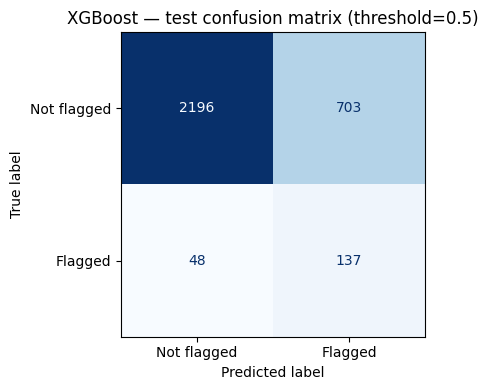

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = test_metrics['confusion_matrix']
cm_array = np.array([[cm['tn'], cm['fp']], [cm['fn'], cm['tp']]])
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm_array, display_labels=['Not flagged', 'Flagged']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'{selected_name} — test confusion matrix (threshold=0.5)')
plt.tight_layout()
plt.savefig('../reports/figures/test_confusion_matrix.png', dpi=150)
plt.show()


## 7. Operational metrics: precision@K / recall@K on the test set

Simulates a fixed analyst review budget: if the queue only reviews the top K% of claims by score, how many of the dataset-flagged claims would be caught?

In [10]:
pr_at_k = precision_recall_at_k(y_test, test_prob, k_fractions=(0.05, 0.10, 0.20))
pr_at_k


,k_fraction,k_n_claims,precision_at_k,recall_at_k,flagged_in_top_k,total_flagged
0,0.05,154,0.246753,0.205405,38,185
1,0.10,308,0.198052,0.329730,61,185
2,0.20,617,0.183144,0.610811,113,185


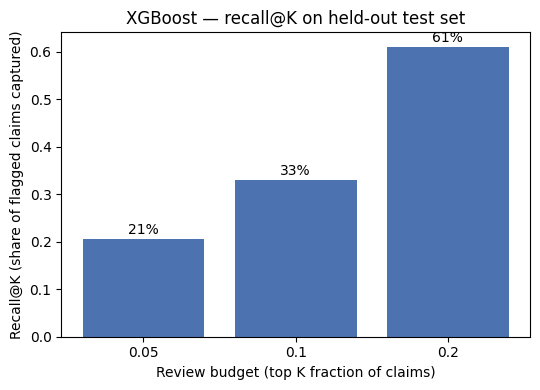

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(pr_at_k['k_fraction'].astype(str), pr_at_k['recall_at_k'], color='#4C72B0')
ax.set_xlabel('Review budget (top K fraction of claims)')
ax.set_ylabel('Recall@K (share of flagged claims captured)')
ax.set_title(f'{selected_name} — recall@K on held-out test set')
for i, v in enumerate(pr_at_k['recall_at_k']):
    ax.text(i, v + 0.01, f'{v:.0%}', ha='center')
plt.tight_layout()
plt.savefig('../reports/figures/recall_at_k_test.png', dpi=150)
plt.show()


## 8. Save model artifact and metrics

In [12]:
Path('../models').mkdir(exist_ok=True)
joblib.dump(selected_pipeline, f'../models/selected_pipeline_{selected_name.replace(" ", "_").lower()}.joblib')

results = {
    'selected_model': selected_name,
    'random_state': RANDOM_STATE,
    'split': {'train_n': len(train_df), 'val_n': len(val_df), 'test_n': len(test_df)},
    'validation_metrics': {
        'logistic_regression': {k: v for k, v in lr_val_metrics.items()},
        'xgboost': {k: v for k, v in xgb_val_metrics.items()},
    },
    'test_metrics_selected_model': test_metrics,
    'precision_recall_at_k_test': pr_at_k.to_dict(orient='records'),
}

import json
with open('../reports/model_results.json', 'w') as f:
    json.dump(results, f, indent=2, default=str)

print('Saved model artifact and reports/model_results.json')
results


Saved model artifact and reports/model_results.json


{'selected_model': 'XGBoost',
 'random_state': 42,
 'split': {'train_n': 9252, 'val_n': 3084, 'test_n': 3084},
 'validation_metrics': {'logistic_regression': {'threshold': 0.5,
   'roc_auc': 0.7977473763118441,
   'pr_auc': 0.15367292382036443,
   'precision': 0.13321647677475898,
   'recall': 0.8260869565217391,
   'f1': 0.22943396226415094,
   'brier_score': 0.17731063218066542,
   'confusion_matrix': {'tn': 1911, 'fp': 989, 'fn': 32, 'tp': 152},
   'positive_prevalence': 0.05966277561608301},
  'xgboost': {'threshold': 0.5,
   'roc_auc': 0.8424812593703149,
   'pr_auc': 0.2553434663491514,
   'precision': 0.1732186732186732,
   'recall': 0.7663043478260869,
   'f1': 0.28256513026052105,
   'brier_score': 0.12743592229518924,
   'confusion_matrix': {'tn': 2227, 'fp': 673, 'fn': 43, 'tp': 141},
   'positive_prevalence': 0.05966277561608301}},
 'test_metrics_selected_model': {'threshold': 0.5,
  'roc_auc': 0.8331633461678305,
  'pr_auc': 0.24192396783908612,
  'precision': 0.1630952380

## 9. Summary (fill after running — do not hand-edit numbers; they come from the cells above)

- **Selected model:** see Section 5 output.
- **Validation PR-AUC** for both candidates: see Section 4 comparison table.
- **Held-out test metrics:** see Section 6 (one-time evaluation — test set was not used for any tuning or model selection decision).
- **Operational read:** see Section 7 — precision@K / recall@K at 5%, 10%, 20% review budgets.
- **Caveats carried forward:** ~6% historical, dataset-defined positive prevalence (1994–1996); scores are *not* calibrated real-world fraud probabilities; human review is still required for any flagged claim.

## 10. Model stability across random seeds

Section 9 of the project plan calls for checking "model stability across random seeds." Everything above used a single `random_state=42`. Here the same XGBoost pipeline is retrained and re-evaluated on 5 different stratified splits (different seeds), to check whether the headline test metrics in Section 6 are representative or a lucky/unlucky draw.

In [13]:
from sklearn.model_selection import train_test_split

seeds = [42, 7, 123, 2024, 999]
stability_rows = []

for seed in seeds:
    tv_df, te_df = train_test_split(df, test_size=0.2, stratify=df['FraudFound_P'], random_state=seed)
    tr_df, _ = train_test_split(tv_df, test_size=0.25, stratify=tv_df['FraudFound_P'], random_state=seed)

    Xtr, ytr = xy(tr_df)
    Xte, yte = xy(te_df)

    spw_seed = compute_scale_pos_weight(ytr)
    pipe_seed = build_xgboost_pipeline(scale_pos_weight=spw_seed)
    pipe_seed.named_steps['model'].set_params(random_state=seed)
    pipe_seed.fit(Xtr, ytr)

    prob_seed = pipe_seed.predict_proba(Xte)[:, 1]
    m_seed = classification_metrics(yte, prob_seed)
    stability_rows.append({'seed': seed, 'roc_auc': m_seed['roc_auc'], 'pr_auc': m_seed['pr_auc'], 'f1': m_seed['f1']})

stability_df = pd.DataFrame(stability_rows)
stability_df


,seed,roc_auc,pr_auc,f1
0,42,0.833163,0.241924,0.267317
1,7,0.858704,0.265018,0.298006
2,123,0.842460,0.242881,0.272641
3,2024,0.852594,0.246361,0.278278
4,999,0.849471,0.256609,0.285714


In [14]:
print('ROC-AUC: mean={:.4f}  std={:.4f}'.format(stability_df['roc_auc'].mean(), stability_df['roc_auc'].std()))
print('PR-AUC:  mean={:.4f}  std={:.4f}'.format(stability_df['pr_auc'].mean(), stability_df['pr_auc'].std()))

stability_results = {
    'per_seed': stability_rows,
    'roc_auc_mean': float(stability_df['roc_auc'].mean()),
    'roc_auc_std': float(stability_df['roc_auc'].std()),
    'pr_auc_mean': float(stability_df['pr_auc'].mean()),
    'pr_auc_std': float(stability_df['pr_auc'].std()),
}
with open('../reports/seed_stability_results.json', 'w') as f:
    json.dump(stability_results, f, indent=2)
print('Saved reports/seed_stability_results.json')


ROC-AUC: mean=0.8473  std=0.0098
PR-AUC:  mean=0.2506  std=0.0100
Saved reports/seed_stability_results.json


**Reading this:** PR-AUC ranges roughly 0.24–0.27 across 5 seeds (std ≈ 0.009 on a mean of ≈0.25, i.e. the seed-to-seed spread is small relative to the headline number). The `random_state=42` result reported as the project's headline metric (PR-AUC 0.242) sits at the **low end** of this range, not a cherry-picked high outlier — if anything, the reported number is conservative relative to the 5-seed average.